E-commerce Sales and Customer Behavior Analysis
Project type: Data Analytics / Data Science portfolio project
Dataset: Online Retail II
Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, SQL, Power BI
Project objectives
1. Clean and validate retail transaction data.
2. Analyse sales, products, countries, and purchasing times.
3. Measure customer purchasing behaviour.
4. Perform RFM-based customer segmentation.
5. Export clean datasets and SQL queries for further analysis.
6. Prepare data for a Power BI dashboard.
Important: Place online_retail_II.xlsx in data/raw/ before running the notebook. Run cells from top to bottom. Do not upload passwords or private credentials to GitHub.

1. Import libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_DIR = Path.cwd().resolve()

# If this notebook is inside the project's notebooks folder, move one level up.
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PLOTS_DIR = PROJECT_DIR / "visualizations"
SQL_DIR = PROJECT_DIR / "sql"
DASHBOARD_DIR = PROJECT_DIR / "dashboard"

for folder in [RAW_DIR, PROCESSED_DIR, PLOTS_DIR, SQL_DIR, DASHBOARD_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Raw data folder:", RAW_DIR)

Project folder: D:\DataScience\Ecommerce-analysis
Raw data folder: D:\DataScience\Ecommerce-analysis\data\raw


2. Load the Online Retail II dataset
The workbook commonly contains two worksheets. This cell reads all worksheets and combines them into one DataFrame. If your workbook has a different number of sheets, it will still read all of them.

In [2]:
excel_path = RAW_DIR / "online_retail_II.xlsx"

if not excel_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {excel_path}\n"
        "Copy online_retail_II.xlsx into the project's data/raw folder."
    )

excel_file = pd.ExcelFile(excel_path, engine="openpyxl")
print("Worksheets found:", excel_file.sheet_names)

frames = []
for sheet in excel_file.sheet_names:
    sheet_df = pd.read_excel(excel_path, sheet_name=sheet, engine="openpyxl")
    sheet_df["source_sheet"] = sheet
    frames.append(sheet_df)

raw_df = pd.concat(frames, ignore_index=True)

print("Combined dataset shape:", raw_df.shape)
display(raw_df.head())

Worksheets found: ['Year 2009-2010', 'Year 2010-2011']
Combined dataset shape: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


3. Initial data exploration
Review the structure, data types, summary statistics, missing values, and duplicates before cleaning.

In [3]:
print("Dataset dimensions:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())

print("\nData types and non-null counts:")
raw_df.info()

display(raw_df.describe(include="all").T)

Dataset dimensions: (1067371, 9)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'source_sheet']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   Invoice       1067371 non-null  object        
 1   StockCode     1067371 non-null  object        
 2   Description   1062989 non-null  object        
 3   Quantity      1067371 non-null  int64         
 4   InvoiceDate   1067371 non-null  datetime64[ns]
 5   Price         1067371 non-null  float64       
 6   Customer ID   824364 non-null   float64       
 7   Country       1067371 non-null  object        
 8   source_sheet  1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 73.3+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,"1,067,371.00","53,628.00","537,434.00","1,350.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"1,067,371.00",NaN,NaN,NaN,9.94,"-80,995.00",1.00,3.00,10.00,"80,995.00",172.71
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394028544,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,"1,067,371.00",NaN,NaN,NaN,4.65,"-53,594.36",1.25,2.10,4.15,"38,970.00",123.55
Customer ID,"824,364.00",NaN,NaN,NaN,"15,324.64","12,346.00","13,975.00","15,255.00","16,797.00","18,287.00","1,697.46"
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_sheet,1067371,2,Year 2010-2011,541910,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
missing_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percentage": (raw_df.isna().mean() * 100).round(2)
}).sort_values("missing_percentage", ascending=False)

display(missing_summary)
print("Duplicate rows:", raw_df.duplicated().sum())

,missing_count,missing_percentage
Customer ID,243007,22.77
Description,4382,0.41
Invoice,0,0.00
Quantity,0,0.00
StockCode,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
source_sheet,0,0.00


Duplicate rows: 12133


4. Standardise column names and prepare a working copy
Column names are converted to lowercase with underscores so they are easier to reference in Python and SQL.

In [5]:
df = raw_df.copy()

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Standardise common Online Retail II column names if necessary.
rename_map = {
    "customer_id": "customer_id",
    "invoicedate": "invoice_date",
    "invoice_date": "invoice_date",
    "stockcode": "stock_code",
    "stock_code": "stock_code",
}
df = df.rename(columns=rename_map)

required_columns = [
    "invoice", "stock_code", "description", "quantity",
    "invoice_date", "price", "customer_id", "country"
]
missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(
        f"Required columns not found: {missing_required}. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Standardised columns:", df.columns.tolist())
display(df.head())

Standardised columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country', 'source_sheet']


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010


5. Data cleaning and preprocessing
   
5.1 Remove exact duplicate rows and convert data types

In [6]:
# Remove the source_sheet column before duplicate detection
df = df.drop(columns=["source_sheet"], errors="ignore")

rows_before = len(df)

df = df.drop_duplicates().copy()

print(
    "Duplicate records removed:",
    rows_before - len(df)
)
print("Exact duplicate rows removed:", rows_before - len(df))

df["invoice_date"] = pd.to_datetime(df["invoice_date"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["customer_id"] = pd.to_numeric(df["customer_id"], errors="coerce")

# Trim text fields without converting missing values into the word 'nan'.
for col in ["invoice", "stock_code", "description", "country"]:
    df[col] = df[col].astype("string").str.strip()

print(df.dtypes)

Duplicate records removed: 34335
Exact duplicate rows removed: 34335
invoice         string[python]
stock_code      string[python]
description     string[python]
quantity                 int64
invoice_date    datetime64[ns]
price                  float64
customer_id            float64
country         string[python]
dtype: object


5.2 Check missing and invalid critical transaction fields
Customer ID and description can be missing in retail datasets. We retain transactions with missing Customer ID for overall sales analysis, but exclude them from customer-level analysis later.

In [7]:
critical_before = len(df)

df = df.dropna(
    subset=["invoice", "stock_code", "quantity", "invoice_date", "price", "country"]
).copy()

print("Rows removed for missing critical fields:", critical_before - len(df))
print("Rows with missing Customer ID retained:", df["customer_id"].isna().sum())
print("Rows with missing description:", df["description"].isna().sum())

print("Non-positive quantity rows:", (df["quantity"] <= 0).sum())
print("Non-positive price rows:", (df["price"] <= 0).sum())

Rows removed for missing critical fields: 0
Rows with missing Customer ID retained: 235151
Rows with missing description: 4275
Non-positive quantity rows: 22496
Non-positive price rows: 6019


5.3 Identify cancellations, returns, and non-product/service codes
Invoices beginning with C are flagged as cancellations. Negative quantities are also flagged as return-like transactions. A short list of common service/non-product codes is used as a transparent filter; review this list against your dataset before relying on the results.

In [8]:
df["is_cancellation"] = (
    df["invoice"].astype("string").str.upper().str.startswith("C", na=False)
)

# Common Online Retail II service / non-merchandise stock codes.
non_product_codes = {
    "POST", "DOT", "M", "BANK CHARGES", "ADJUST", "ADJUST2",
    "AMAZONFEE", "C2", "CRUK", "S", "B", "D", "TEST001", "TEST002"
}

df["is_non_product"] = (
    df["stock_code"].astype("string").str.upper().isin(non_product_codes)
)

df["line_value"] = df["quantity"] * df["price"]

print("Cancellation rows:", int(df["is_cancellation"].sum()))
print("Negative quantity rows:", int((df["quantity"] < 0).sum()))
print("Non-product/service rows:", int(df["is_non_product"].sum()))

Cancellation rows: 19104
Negative quantity rows: 22496
Non-product/service rows: 5699


5.4 Create the final sales dataset
For sales performance, retain positive-quantity, positive-price, non-cancellation merchandise transactions. Keep rows with missing Customer ID so that overall revenue is not unnecessarily lost.

In [9]:
sales_df = df.loc[
    (~df["is_cancellation"]) &
    (~df["is_non_product"]) &
    (df["quantity"] > 0) &
    (df["price"] > 0)
].copy()

sales_df["line_value"] = sales_df["quantity"] * sales_df["price"]

# Add useful time columns for analysis.
sales_df["year"] = sales_df["invoice_date"].dt.year
sales_df["month"] = sales_df["invoice_date"].dt.month
sales_df["year_month"] = sales_df["invoice_date"].dt.to_period("M").astype(str)
sales_df["hour"] = sales_df["invoice_date"].dt.hour
sales_df["day_name"] = sales_df["invoice_date"].dt.day_name()

print("Raw cleaned rows:", len(df))
print("Final sales rows:", len(sales_df))
print("Final sales dataset shape:", sales_df.shape)
display(sales_df.head())

Raw cleaned rows: 1033036
Final sales rows: 1003434
Final sales dataset shape: (1003434, 16)


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,is_cancellation,is_non_product,line_value,year,month,year_month,hour,day_name
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False,False,83.40,2009,12,2009-12,7,Tuesday
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,False,81.00,2009,12,2009-12,7,Tuesday
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False,False,81.00,2009,12,2009-12,7,Tuesday
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,False,False,100.80,2009,12,2009-12,7,Tuesday
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,False,False,30.00,2009,12,2009-12,7,Tuesday


5.5 Validate the final sales dataset

In [10]:
validation = {
    "missing_invoice": int(sales_df["invoice"].isna().sum()),
    "missing_invoice_date": int(sales_df["invoice_date"].isna().sum()),
    "non_positive_quantity": int((sales_df["quantity"] <= 0).sum()),
    "non_positive_price": int((sales_df["price"] <= 0).sum()),
    "duplicate_rows": int(sales_df.duplicated().sum()),
    "missing_customer_id_retained": int(sales_df["customer_id"].isna().sum())
}

display(pd.DataFrame(validation.items(), columns=["check", "count"]))

assert validation["missing_invoice"] == 0
assert validation["missing_invoice_date"] == 0
assert validation["non_positive_quantity"] == 0
assert validation["non_positive_price"] == 0

print("Core sales-data validation passed.")

,check,count
0,missing_invoice,0
1,missing_invoice_date,0
2,non_positive_quantity,0
3,non_positive_price,0
4,duplicate_rows,0
5,missing_customer_id_retained,226838


Core sales-data validation passed.


6. Sales performance analysis
Calculate key business metrics from the final sales dataset. Revenue is expressed in the dataset's original currency (the Online Retail II dataset is commonly denominated in GBP).

In [11]:
total_revenue = sales_df["line_value"].sum()
total_orders = sales_df["invoice"].nunique()
identified_customers = sales_df["customer_id"].nunique()
total_units_sold = sales_df["quantity"].sum()

order_totals = sales_df.groupby("invoice")["line_value"].sum()
average_order_value = order_totals.mean()

sales_kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Identified Customers",
        "Total Units Sold",
        "Average Order Value"
    ],
    "Value": [
        total_revenue,
        total_orders,
        identified_customers,
        total_units_sold,
        average_order_value
    ]
})

display(sales_kpis)
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Identified Customers: {identified_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

,Metric,Value
0,Total Revenue,"19,645,617.81"
1,Total Orders,"39,516.00"
2,Identified Customers,"5,852.00"
3,Total Units Sold,"11,188,141.00"
4,Average Order Value,497.16


Total Revenue: £19,645,617.81
Total Orders: 39,516
Identified Customers: 5,852
Average Order Value: £497.16


6.1 Returns and cancellations
This section estimates the value of merchandise returns using negative-quantity rows. It does not assume every cancellation record represents a separately refunded payment; interpret this as a transaction-data return estimate.

In [12]:
returns_df = df.loc[
    (df["quantity"] < 0) &
    (df["price"] > 0) &
    (~df["is_non_product"])
].copy()

returns_df["return_value"] = returns_df["quantity"].abs() * returns_df["price"]

return_value = returns_df["return_value"].sum()
net_revenue_estimate = total_revenue - return_value
return_value_rate = (return_value / total_revenue * 100) if total_revenue else 0

return_kpis = pd.DataFrame({
    "Metric": ["Gross sales value", "Estimated return value", "Estimated net sales value",
               "Return value as % of gross sales"],
    "Value": [total_revenue, return_value, net_revenue_estimate, return_value_rate]
})
display(return_kpis)

,Metric,Value
0,Gross sales value,"19,645,617.81"
1,Estimated return value,"716,532.13"
2,Estimated net sales value,"18,929,085.68"
3,Return value as % of gross sales,3.65


7. Exploratory Data Analysis (EDA)
Each chart is saved in the visualizations folder. Use the actual chart output to write your observations; do not assume which month, country, or product is highest.

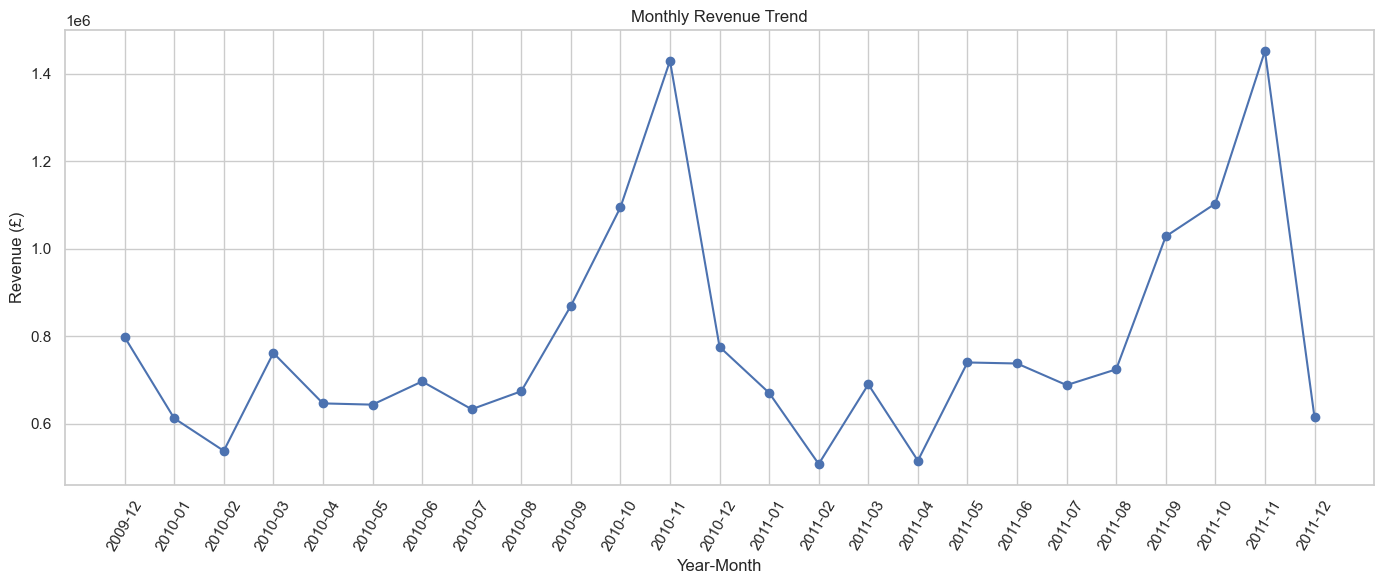

In [13]:
# 7.1 Monthly revenue trend
monthly_revenue = (
    sales_df.groupby("year_month")["line_value"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 6))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

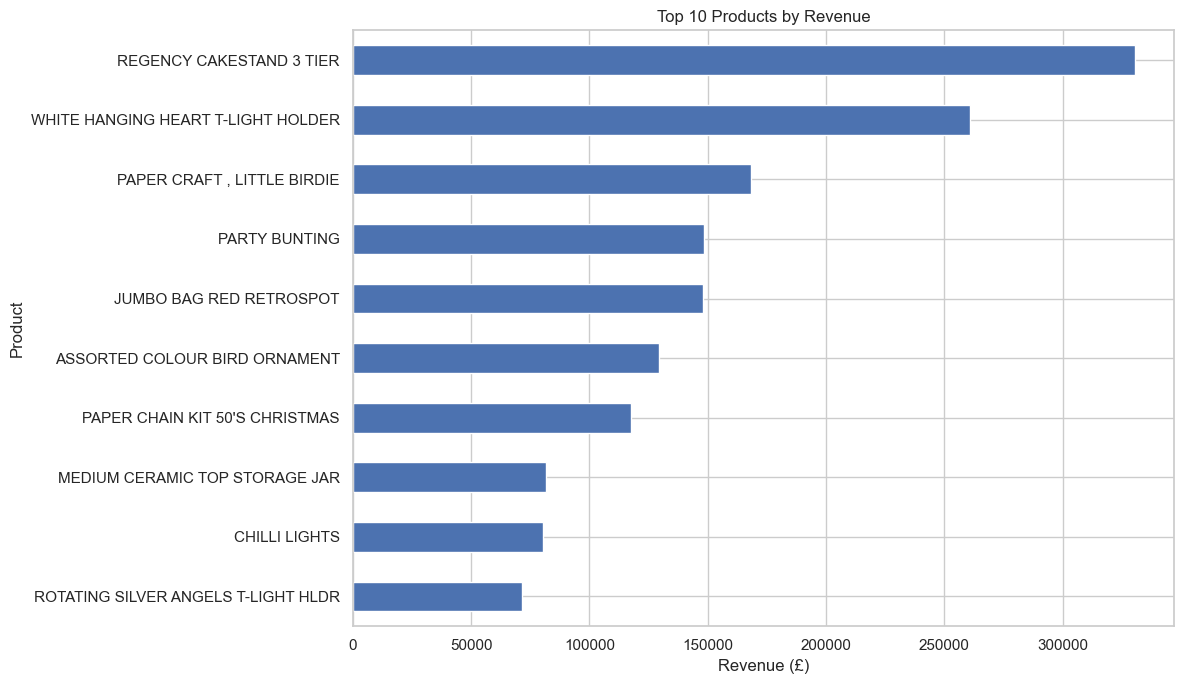

,description,line_value
0,REGENCY CAKESTAND 3 TIER,"330,590.32"
1,WHITE HANGING HEART T-LIGHT HOLDER,"260,990.22"
2,"PAPER CRAFT , LITTLE BIRDIE","168,469.60"
3,PARTY BUNTING,"148,318.28"
4,JUMBO BAG RED RETROSPOT,"148,073.47"
5,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49"
6,PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.29"
7,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92"
8,CHILLI LIGHTS,"80,540.88"
9,ROTATING SILVER ANGELS T-LIGHT HLDR,"71,300.40"


In [14]:
# 7.2 Top 10 products by revenue
product_revenue = (
    sales_df.groupby("description")["line_value"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))
product_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "top_products_by_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

display(product_revenue.reset_index())

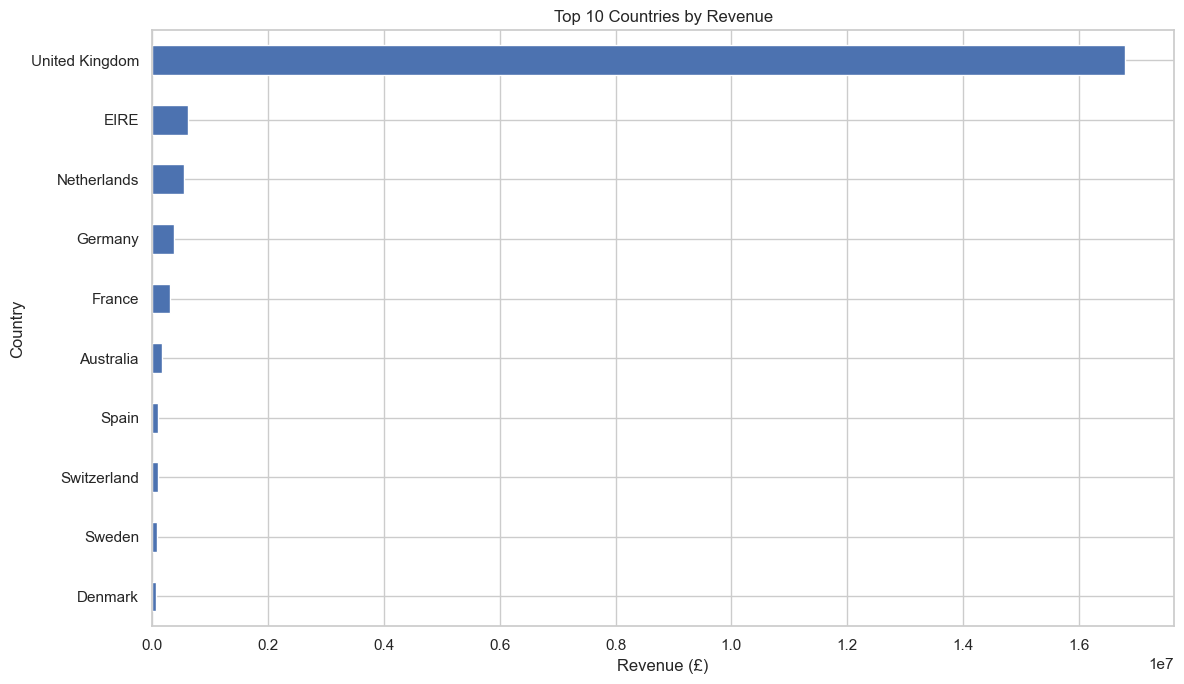

,country,line_value
0,United Kingdom,"16,802,775.56"
1,EIRE,"623,414.16"
2,Netherlands,"549,773.41"
3,Germany,"383,289.00"
4,France,"311,090.29"
5,Australia,"167,800.01"
6,Spain,"97,766.75"
7,Switzerland,"94,024.59"
8,Sweden,"86,319.14"
9,Denmark,"67,422.69"


In [15]:
# 7.3 Top 10 countries by revenue
country_revenue = (
    sales_df.groupby("country")["line_value"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))
country_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "top_countries_by_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

display(country_revenue.reset_index())

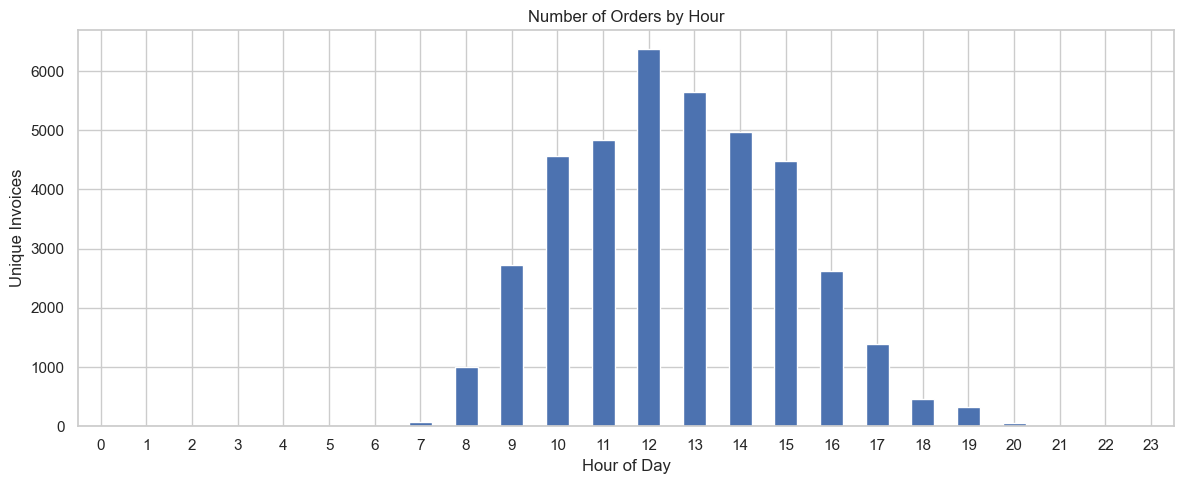

In [16]:
# 7.4 Orders by hour
orders_by_hour = (
    sales_df.groupby("hour")["invoice"]
    .nunique()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(12, 5))
orders_by_hour.plot(kind="bar")
plt.title("Number of Orders by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Unique Invoices")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "orders_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

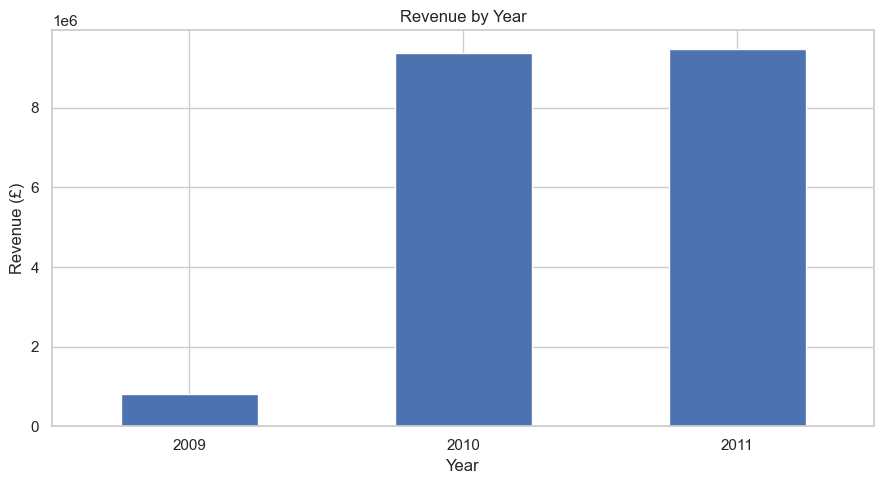

,year,line_value
0,2009,"798,118.53"
1,2010,"9,375,309.09"
2,2011,"9,472,190.18"


In [17]:
# 7.5 Revenue by year
yearly_revenue = sales_df.groupby("year")["line_value"].sum()

plt.figure(figsize=(9, 5))
yearly_revenue.plot(kind="bar")
plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "revenue_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

display(yearly_revenue.reset_index())

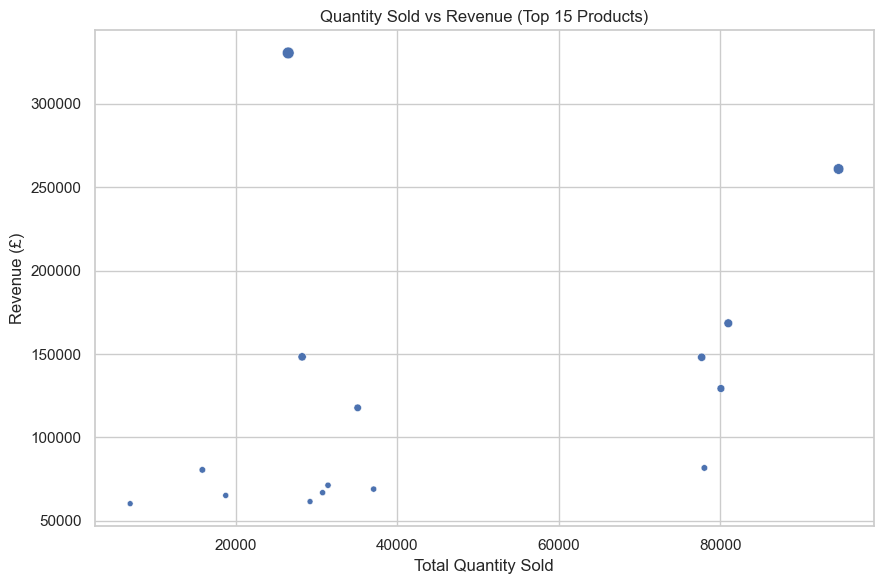

,total_quantity,total_revenue
description,,
REGENCY CAKESTAND 3 TIER,26478,"330,590.32"
WHITE HANGING HEART T-LIGHT HOLDER,94658,"260,990.22"
"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60"
PARTY BUNTING,28200,"148,318.28"
JUMBO BAG RED RETROSPOT,77699,"148,073.47"
ASSORTED COLOUR BIRD ORNAMENT,80082,"129,324.49"
PAPER CHAIN KIT 50'S CHRISTMAS,35084,"117,760.29"
MEDIUM CERAMIC TOP STORAGE JAR,78033,"81,700.92"
CHILLI LIGHTS,15841,"80,540.88"


In [18]:
# 7.6 Quantity sold versus revenue by product (top 15 by revenue)
product_summary = (
    sales_df.groupby("description")
    .agg(total_quantity=("quantity", "sum"),
         total_revenue=("line_value", "sum"))
    .sort_values("total_revenue", ascending=False)
    .head(15)
)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=product_summary,
    x="total_quantity",
    y="total_revenue",
    size="total_revenue",
    legend=False
)
plt.title("Quantity Sold vs Revenue (Top 15 Products)")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "quantity_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

display(product_summary)

8. Customer behavior analysis
Customer-level analysis requires a Customer ID. Transactions without Customer ID remain in sales totals but are excluded from these customer metrics.

In [19]:
identified_sales = sales_df.dropna(subset=["customer_id"]).copy()
identified_sales["customer_id"] = identified_sales["customer_id"].astype("int64")

customer_order_counts = (
    identified_sales.groupby("customer_id")["invoice"].nunique()
)

one_time_customers = int((customer_order_counts == 1).sum())
repeat_customers = int((customer_order_counts > 1).sum())
customer_count = len(customer_order_counts)
repeat_customer_pct = (repeat_customers / customer_count * 100) if customer_count else 0

print("Identified customers:", customer_count)
print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)
print(f"Repeat customer percentage: {repeat_customer_pct:.2f}%")

Identified customers: 5852
One-time customers: 1618
Repeat customers: 4234
Repeat customer percentage: 72.35%


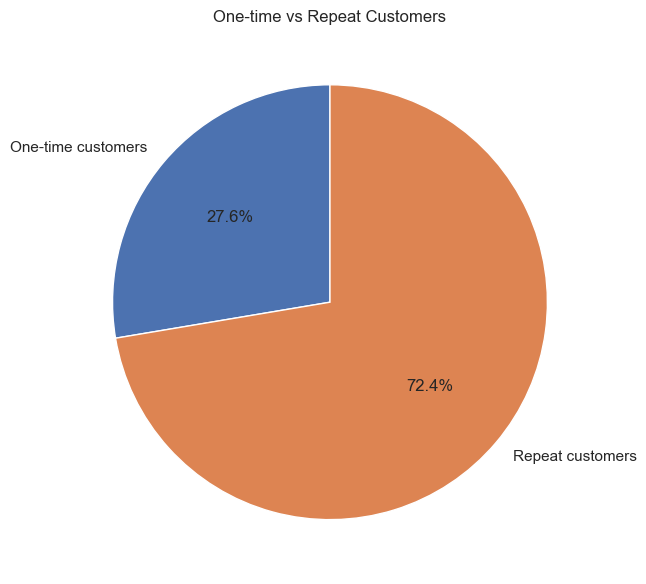

In [20]:
# 8.1 One-time versus repeat customers
customer_type_counts = pd.Series({
    "One-time customers": one_time_customers,
    "Repeat customers": repeat_customers
})

plt.figure(figsize=(7, 6))
customer_type_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("One-time vs Repeat Customers")
plt.ylabel("")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "one_time_vs_repeat_customers.png", dpi=150, bbox_inches="tight")
plt.show()

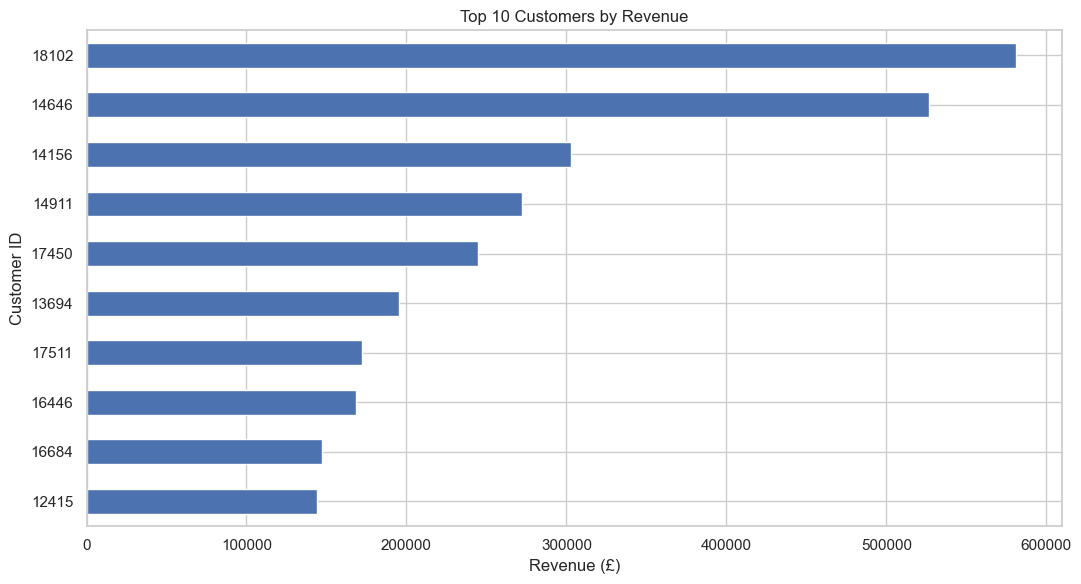

,customer_id,line_value
0,18102,"580,987.04"
1,14646,"526,751.52"
2,14156,"303,069.88"
3,14911,"272,252.79"
4,17450,"244,784.25"
5,13694,"195,640.69"
6,17511,"172,132.87"
7,16446,"168,472.50"
8,16684,"147,142.77"
9,12415,"144,033.37"


In [21]:
# 8.2 Top 10 customers by revenue
top_customers = (
    identified_sales.groupby("customer_id")["line_value"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))
top_customers.sort_values().plot(kind="barh")
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "top_customers.png", dpi=150, bbox_inches="tight")
plt.show()

display(top_customers.reset_index())

9. RFM analysis and customer segmentation
RFM stands for:
- Recency: Number of days since the customer's latest purchase.
- Frequency: Number of distinct invoices/orders.
- Monetary: Total customer spending.
The snapshot date is one day after the latest transaction in the dataset. The segments below are simple rule-based labels based on RFM scores, not a trained machine-learning model.

In [22]:
snapshot_date = sales_df["invoice_date"].max() + pd.Timedelta(days=1)

rfm = (
    identified_sales.groupby("customer_id")
    .agg(
        Recency=("invoice_date", lambda dates: (snapshot_date - dates.max()).days),
        Frequency=("invoice", "nunique"),
        Monetary=("line_value", "sum")
    )
)

display(rfm.head())
print("Customers included in RFM:", len(rfm))

,Recency,Frequency,Monetary
customer_id,,,
12346,326,3,"77,352.96"
12347,2,8,"4,921.53"
12348,75,5,"1,658.40"
12349,19,3,"3,678.69"
12350,310,1,294.40


Customers included in RFM: 5852


In [23]:
# Assign quintile scores. rank(method='first') helps qcut handle tied values.
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head())

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
customer_id,,,,,,,
12346,326,3,"77,352.96",2,3,5,235
12347,2,8,"4,921.53",5,4,5,545
12348,75,5,"1,658.40",3,4,4,344
12349,19,3,"3,678.69",5,3,5,535
12350,310,1,294.40,2,1,2,212


In [24]:
def assign_segment(row):
    # Simple, explainable rules. These can be refined after reviewing results.
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"
    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Potential Loyalists"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Hibernating"
    else:
        return "Others"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Segment", "size"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Total_Monetary=("Monetary", "sum")
    )
    .sort_values("Customers", ascending=False)
)

display(segment_summary)

,Customers,Average_Recency,Average_Frequency,Total_Monetary
Segment,,,,
Hibernating,1511,456.39,1.25,"620,553.60"
Champions,1280,19.65,17.04,"11,598,734.29"
Others,1081,74.87,2.50,"994,475.25"
At Risk,830,367.58,4.98,"1,595,499.35"
Loyal Customers,702,83.01,7.68,"1,843,430.34"
Potential Loyalists,448,27.92,1.46,"415,889.90"


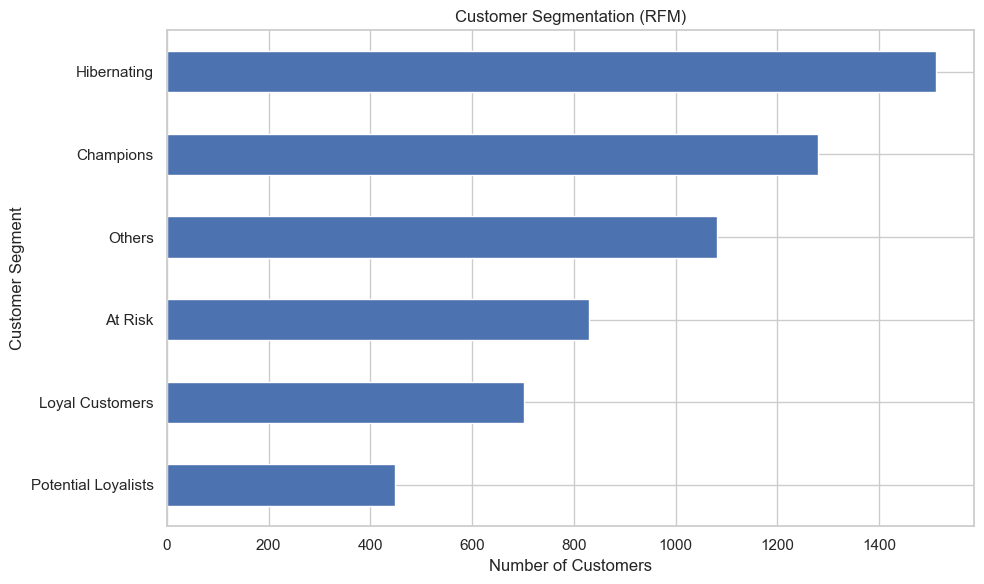

In [25]:
# 9.1 Customer segment distribution
plt.figure(figsize=(10, 6))
segment_summary["Customers"].sort_values().plot(kind="barh")
plt.title("Customer Segmentation (RFM)")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "rfm_customer_segments.png", dpi=150, bbox_inches="tight")
plt.show()

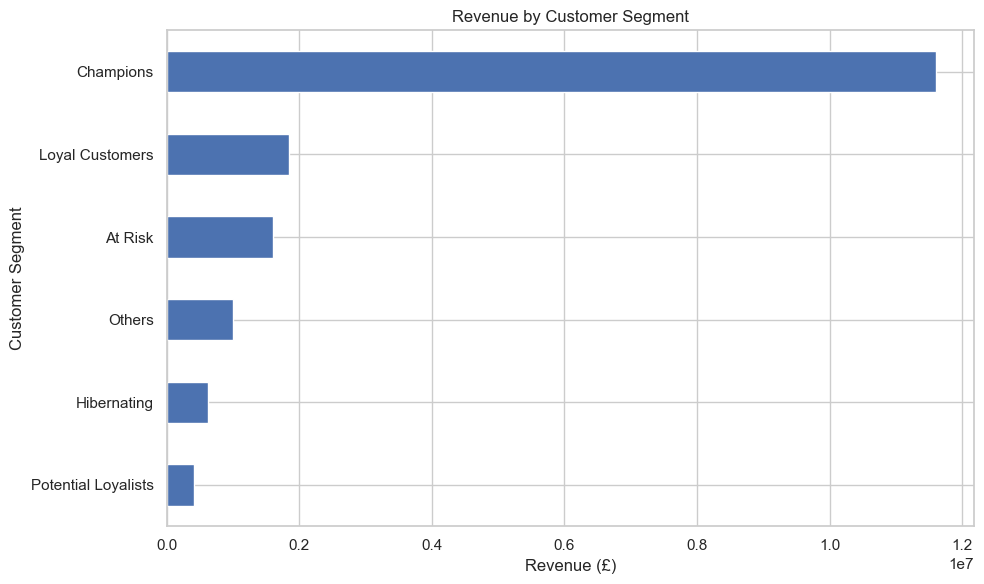

In [26]:
# 9.2 Revenue by RFM segment
plt.figure(figsize=(10, 6))
segment_summary["Total_Monetary"].sort_values().plot(kind="barh")
plt.title("Revenue by Customer Segment")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "revenue_by_customer_segment.png", dpi=150, bbox_inches="tight")
plt.show()

10. Export cleaned datasets for SQL and Power BI
The following files will be saved in data/processed/:
- online_retail_sales.csv: transaction-level sales data.
- customer_rfm.csv: customer RFM scores and segments.
- monthly_revenue.csv: monthly revenue summary.
- country_revenue.csv: country revenue summary.
- product_revenue.csv: product revenue summary.

In [27]:
sales_export = sales_df.copy()
sales_export["customer_id"] = sales_export["customer_id"].astype("Int64")

sales_export.to_csv(PROCESSED_DIR / "online_retail_sales.csv", index=False)
rfm.reset_index().to_csv(PROCESSED_DIR / "customer_rfm.csv", index=False)
monthly_revenue.rename("revenue").reset_index().to_csv(
    PROCESSED_DIR / "monthly_revenue.csv", index=False
)
country_revenue.rename("revenue").reset_index().to_csv(
    PROCESSED_DIR / "country_revenue.csv", index=False
)
product_revenue.rename("revenue").reset_index().to_csv(
    PROCESSED_DIR / "product_revenue.csv", index=False
)

print("Exported files:")
for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print("-", file.name, f"({file.stat().st_size:,} bytes)")

Exported files:
- country_revenue.csv (217 bytes)
- customer_rfm.csv (247,560 bytes)
- monthly_revenue.csv (509 bytes)
- online_retail_sales.csv (134,416,519 bytes)
- product_revenue.csv (414 bytes)


11. SQL analysis queries
This cell creates a .sql file containing useful business queries. Run these queries in MySQL Workbench after importing online_retail_sales.csv into a table named sales.

Note: MySQL date functions and table import settings can vary. Ensure invoice_date is imported as a date/datetime and numeric columns as numeric types.

In [28]:
sql_queries = r'''
-- 1. Total revenue
SELECT SUM(line_value) AS total_revenue
FROM sales;

-- 2. Total orders
SELECT COUNT(DISTINCT invoice) AS total_orders
FROM sales;

-- 3. Top 10 products by revenue
SELECT description, SUM(line_value) AS revenue
FROM sales
GROUP BY description
ORDER BY revenue DESC
LIMIT 10;

-- 4. Revenue by country
SELECT country, SUM(line_value) AS revenue
FROM sales
GROUP BY country
ORDER BY revenue DESC;

-- 5. Monthly revenue
SELECT DATE_FORMAT(invoice_date, '%Y-%m') AS year_month,
       SUM(line_value) AS revenue
FROM sales
GROUP BY DATE_FORMAT(invoice_date, '%Y-%m')
ORDER BY year_month;

-- 6. Top 10 customers by spending
SELECT customer_id, SUM(line_value) AS total_spent
FROM sales
WHERE customer_id IS NOT NULL
GROUP BY customer_id
ORDER BY total_spent DESC
LIMIT 10;

-- 7. Repeat customers
SELECT customer_id, COUNT(DISTINCT invoice) AS order_count
FROM sales
WHERE customer_id IS NOT NULL
GROUP BY customer_id
HAVING COUNT(DISTINCT invoice) > 1
ORDER BY order_count DESC;

-- 8. Average order value
SELECT AVG(order_total) AS average_order_value
FROM (
    SELECT invoice, SUM(line_value) AS order_total
    FROM sales
    GROUP BY invoice
) AS order_summary;
'''

sql_file = SQL_DIR / "analysis_queries.sql"
sql_file.write_text(sql_queries, encoding="utf-8")
print("SQL query file created:", sql_file)

SQL query file created: D:\DataScience\Ecommerce-analysis\sql\analysis_queries.sql


12. Optional: Connect Python to MySQL
This section is optional. You can complete the project analysis and run the saved .sql file in MySQL Workbench without connecting Python directly to MySQL.

13. Key findings and business recommendations
Use the outputs from the notebook to complete this section. Do not copy example conclusions without checking your actual results.

Suggested questions:
1. Which month/year generated the highest revenue?
2. Which products generated the most revenue?
3. Which countries contributed the most sales?
4. What percentage of identified customers made repeat purchases?
5. Which RFM segment has the most customers?
6. Which segment generated the highest revenue?
7. What does the return-value ratio suggest?
Suggested business recommendations:
- Plan inventory around periods of stronger demand.
- Promote products with strong revenue contribution.
- Build loyalty campaigns for repeat customers.
- Re-engage at-risk customers with targeted offers.
- Investigate return patterns and product descriptions.

In [29]:
# 1. Highest revenue month
highest_month = monthly_revenue.idxmax()
highest_month_revenue = monthly_revenue.max()

# 2. Highest revenue product
highest_product = product_revenue.idxmax()
highest_product_revenue = product_revenue.max()

# 3. Highest revenue country
highest_country = country_revenue.idxmax()
highest_country_revenue = country_revenue.max()

# 4. Repeat customer percentage
repeat_percentage = (
    repeat_customers / customer_count * 100
)

# 5. Customer segment with most customers
largest_segment = segment_summary["Customers"].idxmax()
largest_segment_count = segment_summary["Customers"].max()

# 6. Customer segment with highest revenue
highest_segment = segment_summary["Total_Monetary"].idxmax()
highest_segment_revenue = segment_summary["Total_Monetary"].max()

# 7. Return value ratio
print("KEY BUSINESS FINDINGS")
print("-" * 45)

print(f"Highest Revenue Month: {highest_month}")
print(f"Revenue: £{highest_month_revenue:,.2f}")

print(f"\nTop Product: {highest_product}")
print(f"Revenue: £{highest_product_revenue:,.2f}")

print(f"\nTop Country: {highest_country}")
print(f"Revenue: £{highest_country_revenue:,.2f}")

print(f"\nRepeat Customer Percentage: {repeat_percentage:.2f}%")

print(f"\nLargest Customer Segment: {largest_segment}")
print(f"Customers: {largest_segment_count}")

print(f"\nHighest Revenue Segment: {highest_segment}")
print(f"Revenue: £{highest_segment_revenue:,.2f}")

print(f"\nReturn Value Ratio: {return_value_rate:.2f}%")

KEY BUSINESS FINDINGS
---------------------------------------------
Highest Revenue Month: 2011-11
Revenue: £1,452,115.98

Top Product: REGENCY CAKESTAND 3 TIER
Revenue: £330,590.32

Top Country: United Kingdom
Revenue: £16,802,775.56

Repeat Customer Percentage: 72.35%

Largest Customer Segment: Hibernating
Customers: 1511

Highest Revenue Segment: Champions
Revenue: £11,598,734.29

Return Value Ratio: 3.65%


### Key Business Findings

1. **Monthly Revenue:** November 2011 generated the highest revenue of £1,452,115.98.
2. **Product Performance:** REGENCY CAKESTAND 3 TIER was the top revenue-generating product, contributing £330,590.32.
3. **Country Performance:** The United Kingdom was the leading market, generating £16,802,775.56 in revenue.
4. **Repeat Customers:** 72.35% of identified customers made repeat purchases, indicating strong customer retention.
5. **Customer Segmentation:** Hibernating Customers formed the largest segment, with 1,511 customers.
6. **Segment Revenue:** Champions generated the highest revenue of £11,598,734.29.
7. **Returns:** The return value ratio was 3.65%, indicating that returned transactions represent a potential area for revenue improvement.

### Business Recommendations

1. Inventory Management:
   Maintain sufficient inventory for products with
   high sales demand.

2. Product Promotion:
   Focus marketing campaigns on high-revenue products.

3. Customer Retention:
   Introduce loyalty programmes and exclusive offers
   for repeat customers.

4. Customer Re-engagement:
   Send personalised offers to at-risk and
   hibernating customers.

5. Market Expansion:
   Focus on countries generating strong revenue.

6. Return Management:
   Investigate frequently returned products and
   identify possible reasons for returns.

## 14. Power BI Dashboard

An interactive Power BI dashboard was developed to
visualise e-commerce sales and customer behaviour.

### Dashboard Components

- Total Revenue
- Unique Customers
- Top 10 Products by Revenue
- Country-wise Revenue
- Revenue Trend Analysis
- Customer Count by Country

### Data Sources

1. online_retail_sales.csv
2. customer_rfm.csv

### Tools Used

Microsoft Power BI Desktop

The dashboard provides a visual representation
of sales performance and customer distribution.